# T19 -- Weighted core-particle sampling, manual check

**Scope.** This notebook is a visualization/inspection artifact only. No scientific
logic is reimplemented -- every candidate/budget/sampling computation below calls
directly into `iste.candidate_extraction`, `iste.support_features`,
`iste.forward_budget` (T18) and `iste.core_sampling` (T19). No forward propagation,
predicted-slick/KDE construction, or `c_hat*` is computed anywhere here.

**What this demonstrates.** Two synthetic candidate cores at one historical
timestamp `t_s`, deliberately built to exercise BOTH branches of
`README.md` Sec. 17's locked sampling rule:

- **Candidate A**: 25 particles inside its core, budget `X=8` -> `Y >= X` ->
  `iste.core_sampling.sample_core_particles` draws exactly 8 particles WITHOUT
  replacement, using the original Stage III weights as selection probabilities
  (`resampled=True`).
- **Candidate B**: 5 particles inside its core, budget `X=8` -> `Y < X` -> all 5
  particles are retained/selected, unweighted, and the candidate is not rejected
  for having fewer particles than the budget (`resampled=False`).

The figure below plots every core particle (marker size ~ original Stage III
weight) with selected particles in red and unselected particles in gray, the core
boundary as a blue circle, and each candidate's `Y`/`X`/`N_forward`/`resampled`/
`sampling_seed` in its panel title.

In [1]:
import os, sys
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import numpy as np

from iste.particle_query import HistoricalParticleSlice
from iste.kdtree_neighborhood import build_particle_neighborhood_index
from iste.candidate_extraction import Candidate, CoreRegion
from iste.support_features import compute_support_features, SupportFeatureConfig
from iste.forward_budget import ForwardBudgetConfig, compute_forward_particle_budget
from iste.core_sampling import sample_core_particles

## 1. Synthetic historical particle slice: two candidate cores

Candidate A's core (25 particles, `Y >= X`) and candidate B's core (5 particles,
`Y < X`), both at the same historical timestamp `t_s`, with independently-drawn
Stage III `log_weight` per particle (a synthetic gradient, not physically meaningful
-- this is purely to give the weighted-sampling branch a non-uniform weight signal
to visibly favor).

In [2]:
T_S = np.datetime64("2020-01-01T06:00:00", "ns")
NAT = np.datetime64("NaT", "ns")
rng = np.random.default_rng(3)

N_A = 25
lat_a = 20.0 + rng.normal(0.0, 0.006, N_A)
lon_a = 100.0 + rng.normal(0.0, 0.006, N_A)
log_weight_a = rng.normal(0.0, 1.0, N_A)

N_B = 5
lat_b = 23.0 + rng.normal(0.0, 0.006, N_B)
lon_b = 104.0 + rng.normal(0.0, 0.006, N_B)
log_weight_b = rng.normal(0.0, 1.0, N_B)

lat = np.concatenate([lat_a, lat_b])
lon = np.concatenate([lon_a, lon_b])
log_weight = np.concatenate([log_weight_a, log_weight_b])
n = len(lat)
particle_id = np.array([f"p{i:03d}" for i in range(n)], dtype=object)
pix = np.array([f"px-{i % 4}" for i in range(n)], dtype=object)
forcing_member_id = np.zeros(n, dtype=np.int64)
valid = np.ones(n, dtype=bool)

slice_ = HistoricalParticleSlice(
    particle_id=particle_id, observation_pixel_id=pix, forcing_member_id=forcing_member_id,
    lat=lat, lon=lon, log_weight=log_weight, valid=valid,
    death_time=np.full(n, NAT, dtype="datetime64[ns]"),
    death_lat=np.full(n, np.nan), death_lon=np.full(n, np.nan),
    death_reason=np.array([""] * n, dtype=object), query_time=T_S,
)
index = build_particle_neighborhood_index(slice_)
print(f"slice: {slice_.n_particles} particles")

slice: 30 particles


## 2. Candidates (T17 `Candidate`/`CoreRegion`) and T18 forward budgets

Built directly (standing in for real T17 output) so each core's radius is known
exactly; `compute_forward_particle_budget` (T18) then confirms `Y`/`X`/`N_forward`
for each before sampling.

In [3]:
core_a = CoreRegion(center_lat=20.0, center_lon=100.0, radius_m=5000.0)
core_b = CoreRegion(center_lat=23.0, center_lon=104.0, radius_m=5000.0)

sf_a = compute_support_features(index, 20.0, 100.0, radius_m=5000.0, config=SupportFeatureConfig())
sf_b = compute_support_features(index, 23.0, 104.0, radius_m=5000.0, config=SupportFeatureConfig())

cand_a = Candidate(
    candidate_id=f"{np.datetime_as_string(T_S, unit='s')}_cand000", x_peak=100.0, y_peak=20.0,
    t_s=T_S, core_region=core_a, support_score=sf_a.support, density_score=sf_a.density,
    weighted_support_score=sf_a.weighted_support, pixel_diversity_score=sf_a.pixel_diversity,
    peak_support_features=sf_a,
)
cand_b = Candidate(
    candidate_id=f"{np.datetime_as_string(T_S, unit='s')}_cand001", x_peak=104.0, y_peak=23.0,
    t_s=T_S, core_region=core_b, support_score=sf_b.support, density_score=sf_b.density,
    weighted_support_score=sf_b.weighted_support, pixel_diversity_score=sf_b.pixel_diversity,
    peak_support_features=sf_b,
)

config = ForwardBudgetConfig(X=8)
budget_a = compute_forward_particle_budget(cand_a, index, config)
budget_b = compute_forward_particle_budget(cand_b, index, config)
print(f"candidate A: Y={budget_a.Y} X={budget_a.X} N_forward={budget_a.N_forward}")
print(f"candidate B: Y={budget_b.Y} X={budget_b.X} N_forward={budget_b.N_forward}")
assert budget_a.Y >= budget_a.X  # candidate A exercises the weighted-resampling branch
assert budget_b.Y < budget_b.X   # candidate B exercises the retain-all branch

candidate A: Y=25 X=8 N_forward=8
candidate B: Y=5 X=8 N_forward=5


## 3. T19 weighted core-particle sampling

`iste.core_sampling.sample_core_particles` with an explicit `seed` -- reproducible
by construction (the same call with the same seed always returns the same
selection; see `tests/test_core_sampling.py`'s own reproducibility tests for the
automated check).

In [4]:
SEED = 42
result_a = sample_core_particles(cand_a, index, config, seed=SEED)
result_b = sample_core_particles(cand_b, index, config, seed=SEED)
print(f"result A: n_selected={result_a.n_selected} resampled={result_a.resampled}")
print(f"result B: n_selected={result_b.n_selected} resampled={result_b.resampled}")
assert result_a.n_selected == 8 and result_a.resampled
assert result_b.n_selected == 5 and not result_b.resampled

result A: n_selected=8 resampled=True
result B: n_selected=5 resampled=False


## 4. Visualization: core particles, selected vs. unselected, core boundary

Marker size scales with each particle's original Stage III weight (unmodified --
T19 never renormalizes `log_weight`). Selected particles are red, unselected are
gray; the blue circle is the candidate's `core_region`.

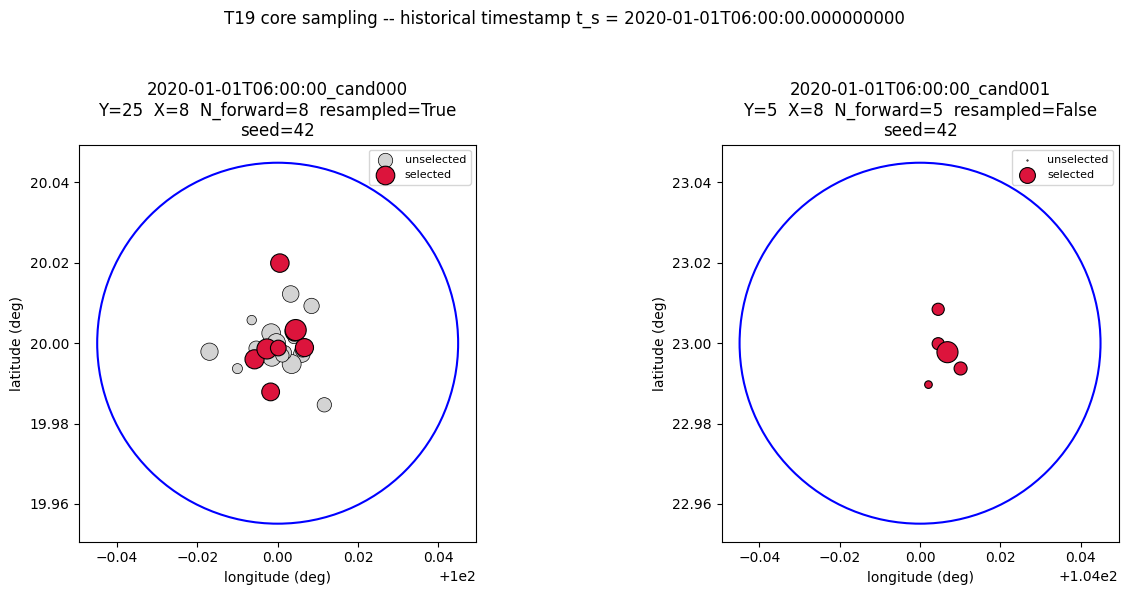

In [5]:
deg_per_m_lat = 1.0 / 111_320.0


def plot_candidate(ax, candidate, result, core_lat, core_lon, core_particle_lat, core_particle_lon,
                    core_particle_weight, core_particle_ids):
    selected_ids = set(result.particle_id.tolist())
    is_selected = np.array([pid in selected_ids for pid in core_particle_ids])

    sizes = 30 + 200 * (core_particle_weight - core_particle_weight.min()) / (
        np.ptp(core_particle_weight) + 1e-12
    )
    ax.scatter(
        core_particle_lon[~is_selected], core_particle_lat[~is_selected],
        s=sizes[~is_selected], c="lightgray", edgecolors="black", linewidths=0.5,
        label="unselected", zorder=3,
    )
    ax.scatter(
        core_particle_lon[is_selected], core_particle_lat[is_selected],
        s=sizes[is_selected], c="crimson", edgecolors="black", linewidths=0.8,
        label="selected", zorder=4,
    )
    radius_deg = candidate.core_region.radius_m * deg_per_m_lat
    ax.add_patch(Circle((core_lon, core_lat), radius=radius_deg, fill=False, edgecolor="blue", linewidth=1.5, zorder=5))
    ax.set_aspect("equal")
    ax.set_xlabel("longitude (deg)")
    ax.set_ylabel("latitude (deg)")
    ax.set_title(
        f"{candidate.candidate_id}\nY={result.Y}  X={result.X}  N_forward={result.N_forward}  "
        f"resampled={result.resampled}\nseed={result.sampling_seed}"
    )
    ax.legend(loc="upper right", fontsize=8)


fig, axes = plt.subplots(1, 2, figsize=(13, 6))
plot_candidate(axes[0], cand_a, result_a, 20.0, 100.0, lat_a, lon_a, log_weight_a, particle_id[:N_A])
plot_candidate(axes[1], cand_b, result_b, 23.0, 104.0, lat_b, lon_b, log_weight_b, particle_id[N_A:])
fig.suptitle(f"T19 core sampling -- historical timestamp t_s = {T_S}", fontsize=12)
fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.94))
plt.show()

## Interpretation limits

- This is a **selection** artifact, not a forward-validation result. No forward
  propagation, predicted-slick/KDE construction, forward scoring, or `c_hat*` is
  computed anywhere in T19 or this notebook.
- Candidate A's weighted selection (`resampled=True`) is an empirical representative
  sample of its core -- a later stage building the forward KDE should use EQUAL
  computational weight per selected particle by default (`README.md` Sec. 17); this
  notebook does not attach or compute any such forward weight.
- Candidate B retains every original core particle (`resampled=False`) with its
  original, un-renormalized `log_weight` -- any normalization for a later forward
  KDE must happen in that later stage, not here (confirmed by
  `tests/test_core_sampling.py`'s `TestOriginalWeightsUnchanged`).
- Selection is reproducible from `sampling_seed` alone; a different seed can produce
  a different selection for the same candidate (see the automated
  `TestReproducibility` tests for both properties).